In [1]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
file_name = next(iter(uploaded))
df = pd.read_excel(file_name)
print("Dataset successfully loaded!")

Dataset successfully loaded!


In [ ]:
df.shape

In [ ]:
df.info()

In [ ]:
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)

missing_percentage = (df.isnull().sum() / len(df)) * 100
print("Missing Value Percentage:")
print(missing_percentage)

In [ ]:
df.describe()

In [ ]:
print("Unique Customers:", df['CustomerID'].nunique())
print("Unique Products:", df['StockCode'].nunique())
print("Unique Invoices:", df['InvoiceNo'].nunique())
print("Unique Countries:", df['Country'].nunique())

In [ ]:
cancelled = df[df['InvoiceNo'].astype(str).str.startswith('C')]

print("Cancelled Transactions:", len(cancelled))
print("Percentage of Cancelled Transactions:",
      (len(cancelled) / len(df)) * 100)

In [14]:
negative_quantity = df[df['Quantity'] < 0]

print("Records with Negative Quantity:", len(negative_quantity))
print("Percentage:", (len(negative_quantity) / len(df)) * 100)

Records with Negative Quantity: 10624
Percentage: 1.9604767590130447


In [15]:
negative_quantity = df[df['Quantity'] < 0]

print("Negative Quantity Records:", len(negative_quantity))

print("Negative Quantity with Cancelled Invoice:",
      negative_quantity['InvoiceNo'].astype(str).str.startswith('C').sum())

print("Negative Quantity without Cancelled Invoice:",
      (~negative_quantity['InvoiceNo'].astype(str).str.startswith('C')).sum())

Negative Quantity Records: 10624
Negative Quantity with Cancelled Invoice: 9288
Negative Quantity without Cancelled Invoice: 1336


In [16]:
negative_price = df[df['UnitPrice'] < 0]

print("Records with Negative Unit Price:", len(negative_price))
print("\nNegative Price Records:")
print(negative_price.head())

Records with Negative Unit Price: 2

Negative Price Records:
       InvoiceNo StockCode      Description  Quantity         InvoiceDate  \
299983   A563186         B  Adjust bad debt         1 2011-08-12 14:51:00   
299984   A563187         B  Adjust bad debt         1 2011-08-12 14:52:00   

        UnitPrice  CustomerID         Country  
299983  -11062.06         NaN  United Kingdom  
299984  -11062.06         NaN  United Kingdom  


In [17]:
zero_price = df[df['UnitPrice'] == 0]

print("Records with Zero Unit Price:", len(zero_price))
print("\nSample Zero Price Records:")
print(zero_price.head())

Records with Zero Unit Price: 2515

Sample Zero Price Records:
     InvoiceNo StockCode Description  Quantity         InvoiceDate  UnitPrice  \
622     536414     22139         NaN        56 2010-12-01 11:52:00        0.0   
1970    536545     21134         NaN         1 2010-12-01 14:32:00        0.0   
1971    536546     22145         NaN         1 2010-12-01 14:33:00        0.0   
1972    536547     37509         NaN         1 2010-12-01 14:33:00        0.0   
1987    536549    85226A         NaN         1 2010-12-01 14:34:00        0.0   

      CustomerID         Country  
622          NaN  United Kingdom  
1970         NaN  United Kingdom  
1971         NaN  United Kingdom  
1972         NaN  United Kingdom  
1987         NaN  United Kingdom  


In [18]:
zero_price = df[df['UnitPrice'] == 0]

print("Zero Price Records:", len(zero_price))

Zero Price Records: 2515


In [ ]:
# Create a copy of the original dataset
clean_df = df.copy()

# Remove cancelled invoices
clean_df = clean_df[
    ~clean_df['InvoiceNo'].astype(str).str.startswith('C')
]

# Remove records with negative or zero quantities
clean_df = clean_df[clean_df['Quantity'] > 0]

# Remove records with negative or zero unit prices
clean_df = clean_df[clean_df['UnitPrice'] > 0]

# Remove records with missing CustomerID or Description
clean_df = clean_df.dropna(subset=['CustomerID', 'Description'])

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Reset index
clean_df = clean_df.reset_index(drop=True)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", clean_df.shape)
print("Remaining Missing Values:", clean_df.isnull().sum().sum())
print("Remaining Duplicate Records:", clean_df.duplicated().sum())

In [ ]:
# Calculate total sales for each transaction
clean_df['TotalSales'] = clean_df['Quantity'] * clean_df['UnitPrice']

# Extract date components
clean_df['Year'] = clean_df['InvoiceDate'].dt.year
clean_df['Month'] = clean_df['InvoiceDate'].dt.month
clean_df['MonthName'] = clean_df['InvoiceDate'].dt.month_name()
clean_df['Date'] = clean_df['InvoiceDate'].dt.date

# Display updated dataset
clean_df.head()

In [ ]:
print("Total Revenue:", round(clean_df['TotalSales'].sum(), 2))
print("Total Transactions:", clean_df['InvoiceNo'].nunique())
print("Total Customers:", clean_df['CustomerID'].nunique())
print("Total Products:", clean_df['StockCode'].nunique())

    Year  Month  MonthName   TotalSales
0   2010     12   December   570422.730
1   2011      1    January   568101.310
2   2011      2   February   446084.920
3   2011      3      March   594081.760
4   2011      4      April   468374.331
5   2011      5        May   677355.150
6   2011      6       June   660046.050
7   2011      7       July   598962.901
8   2011      8     August   644051.040
9   2011      9  September   950690.202
10  2011     10    October  1035642.450
11  2011     11   November  1156205.610
12  2011     12   December   517190.440


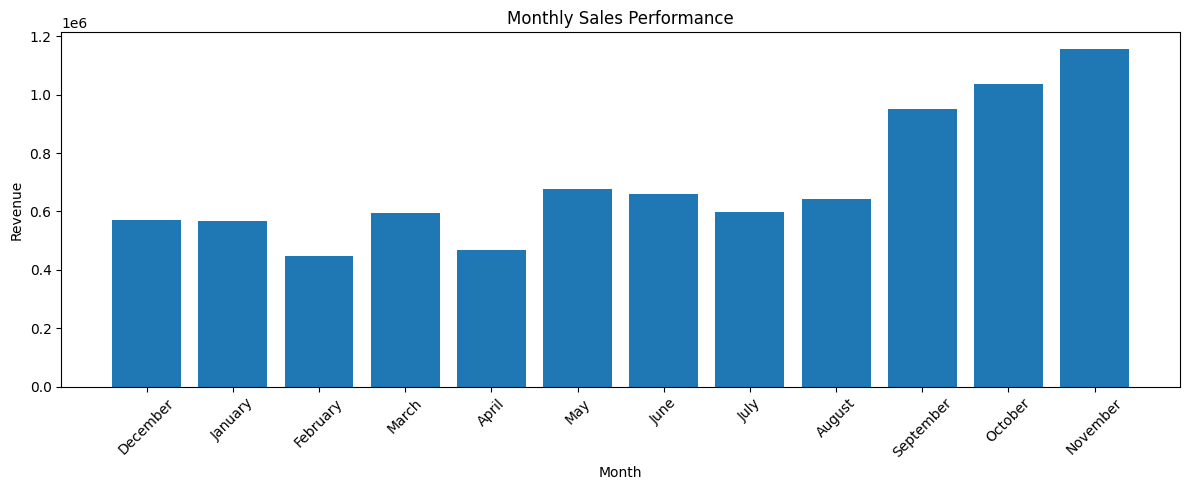

In [22]:
# Calculate monthly revenue
monthly_sales = clean_df.groupby(
    ['Year', 'Month', 'MonthName']
)['TotalSales'].sum().reset_index()

# Sort by year and month
monthly_sales = monthly_sales.sort_values(['Year', 'Month'])

print(monthly_sales)

# Visualize monthly revenue
plt.figure(figsize=(12, 5))
plt.bar(monthly_sales['MonthName'], monthly_sales['TotalSales'])

plt.title('Monthly Sales Performance')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
# Group sales by product
product_sales = clean_df.groupby(
    ['StockCode', 'Description']
).agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Revenue=('TotalSales', 'sum')
).reset_index()

# Top 10 products by revenue
top_products = product_sales.sort_values(
    by='Total_Revenue', ascending=False
).head(10)

print("Top 10 Products by Revenue:")
print(top_products)

Top 10 Products by Revenue:
     StockCode                         Description  Total_Quantity  \
2529     23843         PAPER CRAFT , LITTLE BIRDIE           80995   
1245     22423            REGENCY CAKESTAND 3 TIER           12374   
3576    85123A  WHITE HANGING HEART T-LIGHT HOLDER           36706   
3569    85099B             JUMBO BAG RED RETROSPOT           46078   
2027     23166      MEDIUM CERAMIC TOP STORAGE JAR           77916   
3896      POST                             POSTAGE            3120   
2607     47566                       PARTY BUNTING           15279   
2810     84879       ASSORTED COLOUR BIRD ORNAMENT           35263   
3894         M                              Manual            6933   
1933     23084                  RABBIT NIGHT LIGHT           27153   

      Total_Revenue  
2529      168469.60  
1245      142264.75  
3576      100392.10  
3569       85040.54  
2027       81416.73  
3896       77803.96  
2607       68785.23  
2810       56413.03  
389

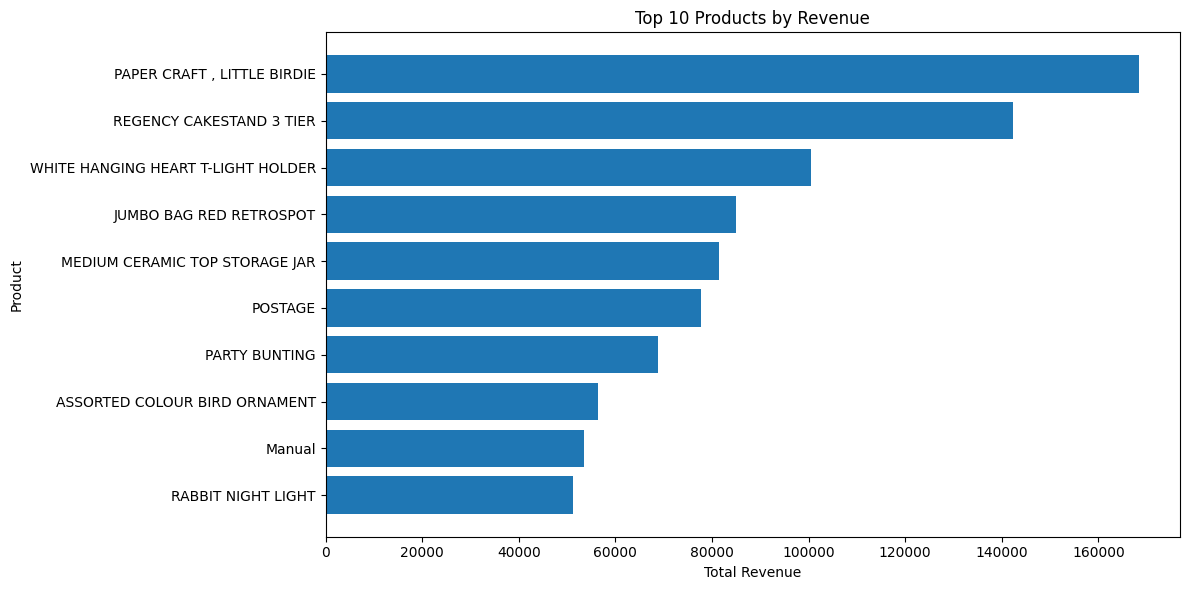

In [24]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_products['Description'],
    top_products['Total_Revenue']
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [25]:
# Create customer-level analysis
customer_analysis = clean_df.groupby('CustomerID').agg(
    Total_Spending=('TotalSales', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Last_Purchase=('InvoiceDate', 'max')
).reset_index()

# Sort customers by total spending
top_customers = customer_analysis.sort_values(
    by='Total_Spending', ascending=False
).head(10)

print("Top 10 Customers by Spending:")
print(top_customers)

# Calculate repeat customers
repeat_customers = customer_analysis[
    customer_analysis['Total_Orders'] > 1
]

print("\nTotal Customers:", len(customer_analysis))
print("Repeat Customers:", len(repeat_customers))
print("Repeat Customer Percentage:",
      round(len(repeat_customers) / len(customer_analysis) * 100, 2), "%")

Top 10 Customers by Spending:
      CustomerID  Total_Spending  Total_Orders  Total_Quantity  \
1689     14646.0       280206.02            73          196915   
4201     18102.0       259657.30            60           64124   
3728     17450.0       194390.79            46           69973   
3008     16446.0       168472.50             2           80997   
1879     14911.0       143711.17           201           80240   
55       12415.0       124914.53            21           77374   
1333     14156.0       117210.08            55           57768   
3771     17511.0        91062.38            31           64549   
2702     16029.0        80850.84            63           40108   
0        12346.0        77183.60             1           74215   

           Last_Purchase  
1689 2011-12-08 12:12:00  
4201 2011-12-09 11:50:00  
3728 2011-12-01 13:29:00  
3008 2011-12-09 09:15:00  
1879 2011-12-08 15:54:00  
55   2011-11-15 14:22:00  
1333 2011-11-30 10:54:00  
3771 2011-12-07 10:12:00  


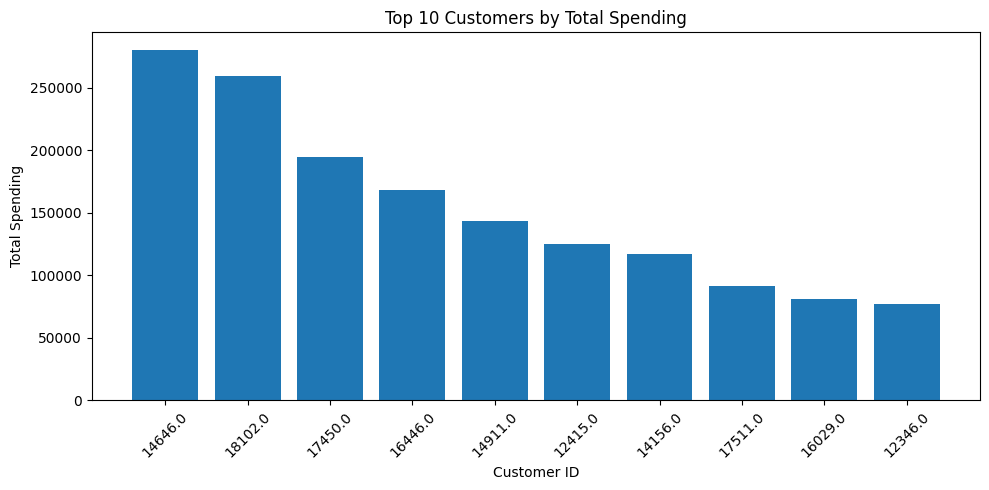

In [26]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_customers['CustomerID'].astype(str),
    top_customers['Total_Spending']
)

plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Customer ID')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# Reference date: one day after the last transaction
reference_date = clean_df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values
rfm = clean_df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalSales', 'sum')
).reset_index()

# Assign scores from 1 to 4
# Lower recency is better; higher frequency and monetary are better
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    4, labels=[4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    4, labels=[1, 2, 3, 4]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    4, labels=[1, 2, 3, 4]
).astype(int)

# Calculate total RFM score
rfm['RFM_Score'] = (
    rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']
)

# Classify customers
def customer_segment(row):
    if row['RFM_Score'] >= 10:
        return 'Best Customers'
    elif row['RFM_Score'] >= 8:
        return 'Loyal Customers'
    elif row['RFM_Score'] >= 6:
        return 'Potential Customers'
    else:
        return 'At Risk Customers'

rfm['Segment'] = rfm.apply(customer_segment, axis=1)

# Display segment counts
print(rfm['Segment'].value_counts())

Segment
At Risk Customers      1295
Best Customers         1260
Potential Customers     940
Loyal Customers         843
Name: count, dtype: int64


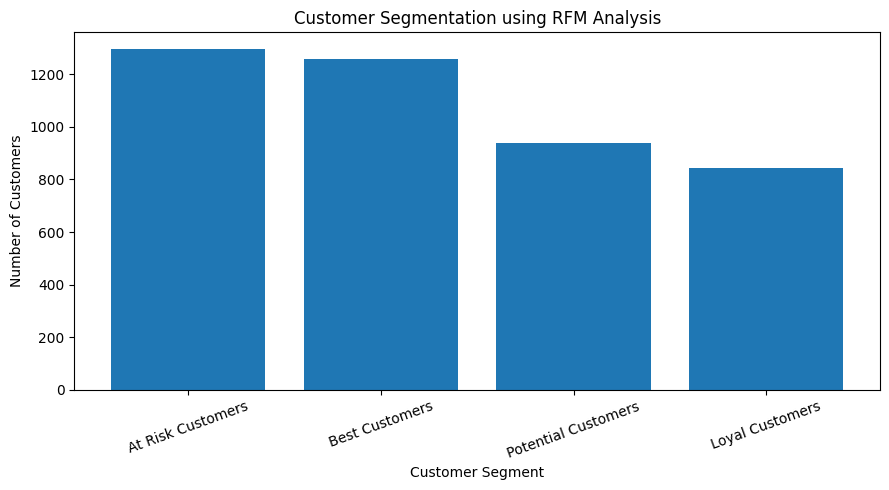

In [28]:
segment_counts = rfm['Segment'].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(segment_counts.index, segment_counts.values)

plt.title('Customer Segmentation using RFM Analysis')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [29]:
# Export cleaned dataset
clean_df.to_csv('cleaned_retail_data.csv', index=False)

# Export customer segmentation
rfm.to_csv('customer_rfm_analysis.csv', index=False)

print("Files exported successfully!")

Files exported successfully!


In [30]:
from google.colab import files

files.download('cleaned_retail_data.csv')
files.download('customer_rfm_analysis.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import sqlite3
import pandas as pd

# Create SQLite database
conn = sqlite3.connect('retail_analysis.db')

# Store cleaned data in SQL table
clean_df.to_sql(
    'retail_transactions',
    conn,
    if_exists='replace',
    index=False
)

# Store customer segmentation in SQL table
rfm.to_sql(
    'customer_rfm',
    conn,
    if_exists='replace',
    index=False
)

print("SQL Database Created Successfully!")

# Verify tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print(tables)

SQL Database Created Successfully!
                  name
0  retail_transactions
1         customer_rfm


In [32]:
query = """
SELECT
    Country,
    ROUND(SUM(TotalSales), 2) AS Total_Revenue
FROM retail_transactions
GROUP BY Country
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

          Country  Total_Revenue
0  United Kingdom     7285024.64
1     Netherlands      285446.34
2            EIRE      265262.46
3         Germany      228678.40
4          France      208934.31
5       Australia      138453.81
6           Spain       61558.56
7     Switzerland       56443.95
8         Belgium       41196.34
9          Sweden       38367.83


In [33]:
# QUERY 1: Top 10 products by revenue
q1 = """
SELECT Description,
       ROUND(SUM(TotalSales), 2) AS Revenue,
       SUM(Quantity) AS Units_Sold
FROM retail_transactions
GROUP BY Description
ORDER BY Revenue DESC
LIMIT 10;
"""

# QUERY 2: Monthly revenue
q2 = """
SELECT Year, Month, MonthName,
       ROUND(SUM(TotalSales), 2) AS Revenue
FROM retail_transactions
GROUP BY Year, Month, MonthName
ORDER BY Year, Month;
"""

# QUERY 3: Customer segmentation
q3 = """
SELECT Segment,
       COUNT(*) AS Customer_Count
FROM customer_rfm
GROUP BY Segment
ORDER BY Customer_Count DESC;
"""

# Execute all queries
print("===== TOP PRODUCTS =====")
print(pd.read_sql_query(q1, conn))

print("\n===== MONTHLY REVENUE =====")
print(pd.read_sql_query(q2, conn))

print("\n===== CUSTOMER SEGMENTS =====")
print(pd.read_sql_query(q3, conn))

===== TOP PRODUCTS =====
                          Description    Revenue  Units_Sold
0         PAPER CRAFT , LITTLE BIRDIE  168469.60       80995
1            REGENCY CAKESTAND 3 TIER  142264.75       12374
2  WHITE HANGING HEART T-LIGHT HOLDER  100392.10       36706
3             JUMBO BAG RED RETROSPOT   85040.54       46078
4      MEDIUM CERAMIC TOP STORAGE JAR   81416.73       77916
5                             POSTAGE   77803.96        3120
6                       PARTY BUNTING   68785.23       15279
7       ASSORTED COLOUR BIRD ORNAMENT   56413.03       35263
8                              Manual   53419.93        6933
9                  RABBIT NIGHT LIGHT   51251.24       27153

===== MONTHLY REVENUE =====
    Year  Month  MonthName     Revenue
0   2010     12   December   570422.73
1   2011      1    January   568101.31
2   2011      2   February   446084.92
3   2011      3      March   594081.76
4   2011      4      April   468374.33
5   2011      5        May   677355.15
6 

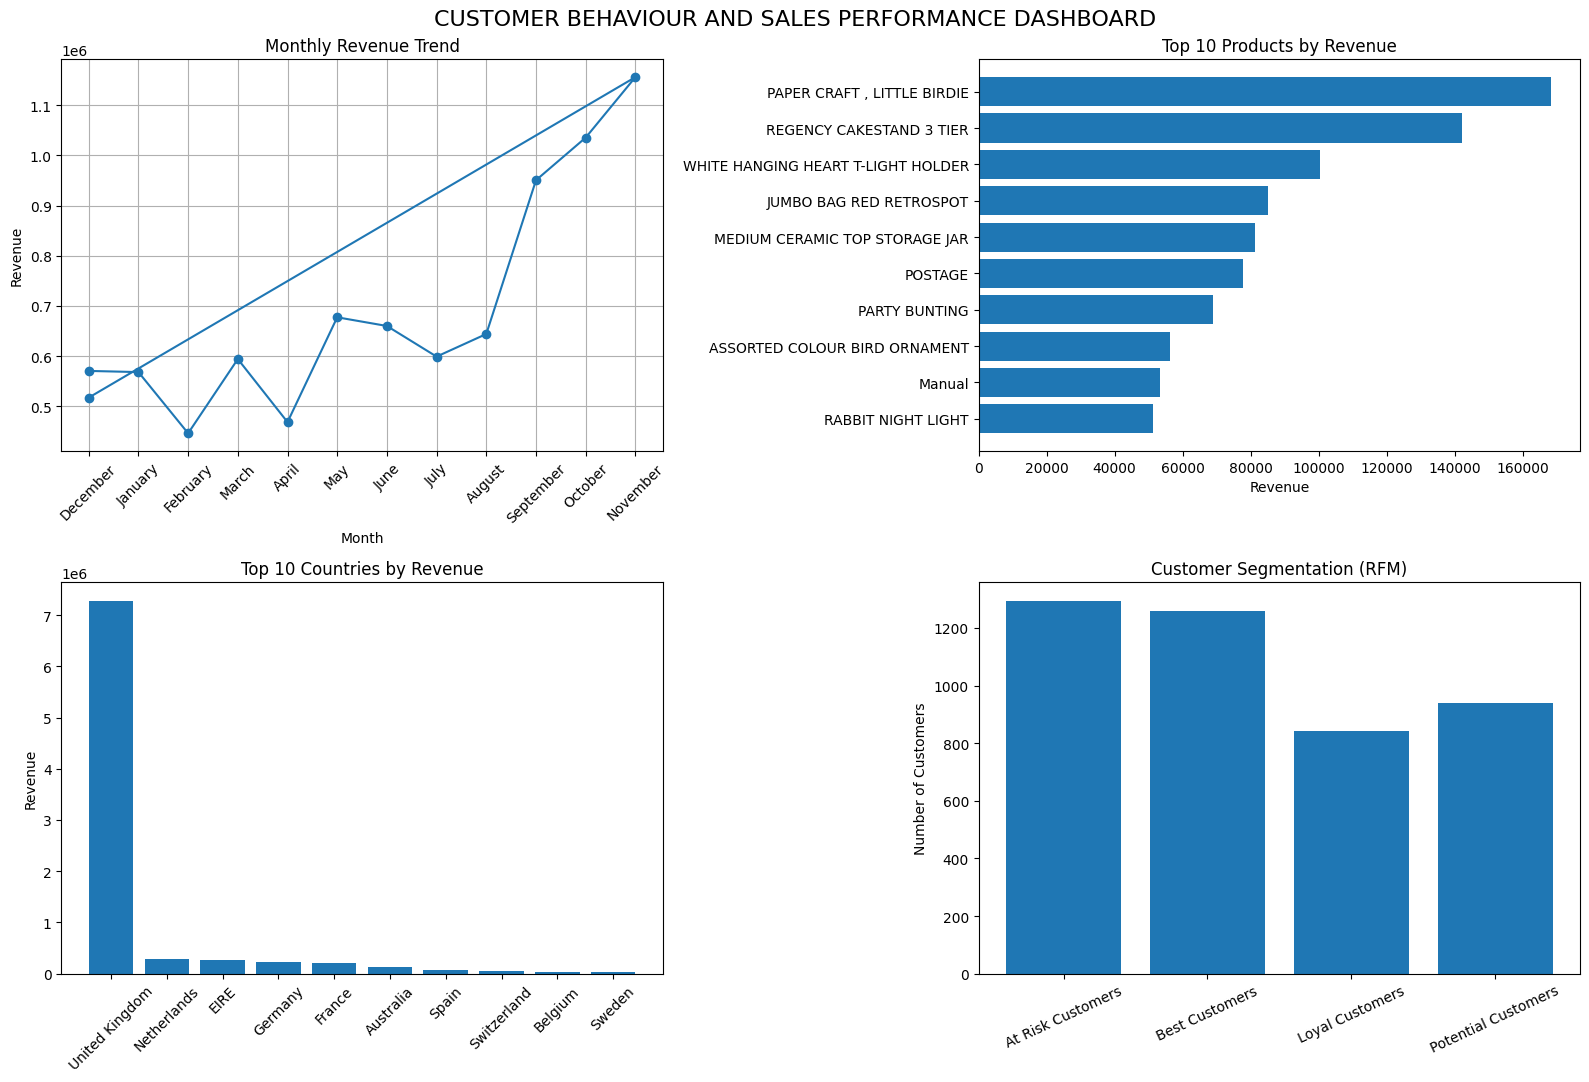

Dashboard created and saved successfully!


In [34]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare data
country_sales = pd.read_sql_query("""
    SELECT Country, SUM(TotalSales) AS Revenue
    FROM retail_transactions
    GROUP BY Country
    ORDER BY Revenue DESC
    LIMIT 10
""", conn)

segment_data = pd.read_sql_query("""
    SELECT Segment, COUNT(*) AS Customers
    FROM customer_rfm
    GROUP BY Segment
""", conn)

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Monthly Revenue
axes[0, 0].plot(
    monthly_sales['MonthName'],
    monthly_sales['TotalSales'],
    marker='o'
)
axes[0, 0].set_title('Monthly Revenue Trend')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Revenue')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True)

# 2. Top Products
axes[0, 1].barh(
    top_products['Description'].head(10),
    top_products['Total_Revenue'].head(10)
)
axes[0, 1].set_title('Top 10 Products by Revenue')
axes[0, 1].set_xlabel('Revenue')
axes[0, 1].invert_yaxis()

# 3. Country Revenue
axes[1, 0].bar(
    country_sales['Country'],
    country_sales['Revenue']
)
axes[1, 0].set_title('Top 10 Countries by Revenue')
axes[1, 0].set_ylabel('Revenue')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Customer Segmentation
axes[1, 1].bar(
    segment_data['Segment'],
    segment_data['Customers']
)
axes[1, 1].set_title('Customer Segmentation (RFM)')
axes[1, 1].set_ylabel('Number of Customers')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.suptitle(
    'CUSTOMER BEHAVIOUR AND SALES PERFORMANCE DASHBOARD',
    fontsize=16
)

plt.tight_layout()
plt.savefig('retail_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

print("Dashboard created and saved successfully!")

In [35]:
from google.colab import files

# Download SQL database
files.download('retail_analysis.db')

# Download dashboard image
files.download('retail_dashboard.png')

# Download notebook
from google.colab import drive

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>